# 04 - Log-Mel Spectrogram Preprocessing and Normalization

**Goal:** turn every audio clip into a fixed-size, normalized log-mel spectrogram, the input to the CNN (Phase 2).

**Pipeline per clip** (same steps as the classical-ML pipeline, so the comparison is fair)
1. Load, convert to mono, resample to 22.05 kHz
2. Trim leading/trailing silence (25 dB threshold)
3. Peak-normalize the amplitude
4. Cap at 4 seconds
5. Mel spectrogram (128 mel bands, FFT 2048, hop 512), converted to decibels (log scale)
6. Pad short clips to a fixed width of 173 frames
7. Normalize with the **training-set** mean and standard deviation

**Input:** `data/split.csv`, `data/clean_metadata.csv`, audio in `data/RAVDESS/`.
**Output:** `data/X_logmel_raw.npy`, `data/X_logmel_norm.npy`, `data/norm_stats.npy`, `data/labels.csv`.

# 0. Imports and settings

In [10]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)
os.makedirs("../data", exist_ok=True)

EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

import json
import librosa, librosa.display
from joblib import Parallel, delayed

SR = 22050            # sample rate (Hz)
TOP_DB = 25           # silence threshold for trimming
MAX_SEC = 4.0         # clips are capped / padded to this length
N_FFT = 2048          # FFT window
HOP = 512             # hop length -> about 23 ms per frame
N_MELS = 128          # mel bands (frequency axis)
MAX_SAMPLES = int(MAX_SEC * SR)
N_FRAMES = 1 + MAX_SAMPLES // HOP     # time axis = 173
print("Target spectrogram shape:", (N_MELS, N_FRAMES))

Target spectrogram shape: (128, 173)


# 1. Load the split and file paths

`split.csv` has the labels and split, `clean_metadata.csv` has each file's path. The row order of `split.csv` is kept, so row *i* of the spectrogram array always matches row *i* of the labels.

In [11]:
split = pd.read_csv("../data/split.csv")
paths = pd.read_csv("../data/clean_metadata.csv")[["filename", "path"]]
lab = split.merge(paths, on="filename", how="left")
assert len(lab) == len(split) and lab["path"].notna().all()

LABEL2ID = {e: i for i, e in enumerate(EMOTIONS)}     # neutral=0 ... surprised=7
lab["label"] = lab["emotion"].map(LABEL2ID)
print(lab["split"].value_counts())
lab.head()

split
train    899
test     300
val      240
Name: count, dtype: int64


,filename,actor,gender,emotion,emotion_id,intensity,split,path,label
0,03-01-01-01-01-01-01.wav,1,male,neutral,1,normal,test,..\data\RAVDESS\Actor_01\03-01-01-01-01-01-01.wav,0
1,03-01-01-01-01-02-01.wav,1,male,neutral,1,normal,test,..\data\RAVDESS\Actor_01\03-01-01-01-01-02-01.wav,0
2,03-01-01-01-02-01-01.wav,1,male,neutral,1,normal,test,..\data\RAVDESS\Actor_01\03-01-01-01-02-01-01.wav,0
3,03-01-01-01-02-02-01.wav,1,male,neutral,1,normal,test,..\data\RAVDESS\Actor_01\03-01-01-01-02-02-01.wav,0
4,03-01-02-01-01-01-01.wav,1,male,calm,2,normal,test,..\data\RAVDESS\Actor_01\03-01-02-01-01-01-01.wav,1


# 2. Log-mel function



In [12]:
def logmel(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = np.nan_to_num(y)
    yt, _ = librosa.effects.trim(y, top_db=TOP_DB)
    if len(yt) < int(0.3 * SR):            # trimming removed (almost) everything
        yt = y
    peak = np.max(np.abs(yt))
    if peak > 0:
        yt = yt / peak                      # amplitude normalization
    yt = yt[:MAX_SAMPLES]                   # cap at 4 s

    S = librosa.feature.melspectrogram(y=yt, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    S = librosa.power_to_db(S, ref=1.0, top_db=80.0)

    n_valid = min(S.shape[1], N_FRAMES)
    S = S[:, :N_FRAMES]
    if S.shape[1] < N_FRAMES:               # pad on the right with the silence floor
        S = np.pad(S, ((0, 0), (0, N_FRAMES - S.shape[1])), constant_values=S.min())
    return S.astype(np.float32), n_valid

S_test, nv = logmel(lab.loc[0, "path"])
print("example shape:", S_test.shape, "| valid frames:", nv)

example shape: (128, 173) | valid frames: 57


# 3. Build the spectrogram array for all clips (about 1-3 minutes)

In [13]:
results = Parallel(n_jobs=-1)(delayed(logmel)(p) for p in lab["path"])
X = np.stack([r[0] for r in results])            # (n_clips, 128, 173)
lab["n_valid_frames"] = [r[1] for r in results]
print("X shape:", X.shape, "| dtype:", X.dtype)

X shape: (1439, 128, 173) | dtype: float32


# 4. Validation checks

In [14]:
print("NaN values:", int(np.isnan(X).sum()), "| inf values:", int(np.isinf(X).sum()))
print("dB range: min %.1f, max %.1f, mean %.1f" % (X.min(), X.max(), X.mean()))
print("Row count matches labels:", X.shape[0] == len(lab))
print("\nValid (non-padded) frames per clip:")
print(lab["n_valid_frames"].describe().round(1))
print("Clips that fill the whole 4 s window:", int((lab["n_valid_frames"] >= N_FRAMES).sum()))

NaN values: 0 | inf values: 0
dB range: min -58.2, max 39.7, mean -34.6
Row count matches labels: True

Valid (non-padded) frames per clip:
count    1439.0
mean       77.8
std        16.4
min        46.0
25%        67.0
50%        74.0
75%        86.0
max       151.0
Name: n_valid_frames, dtype: float64
Clips that fill the whole 4 s window: 0


Every clip now has the same shape, so a batch can be stacked directly for the CNN. The `n_valid_frames` summary shows how much of each spectrogram is real audio and how much is padding.

# 5. Visual check: one spectrogram per emotion

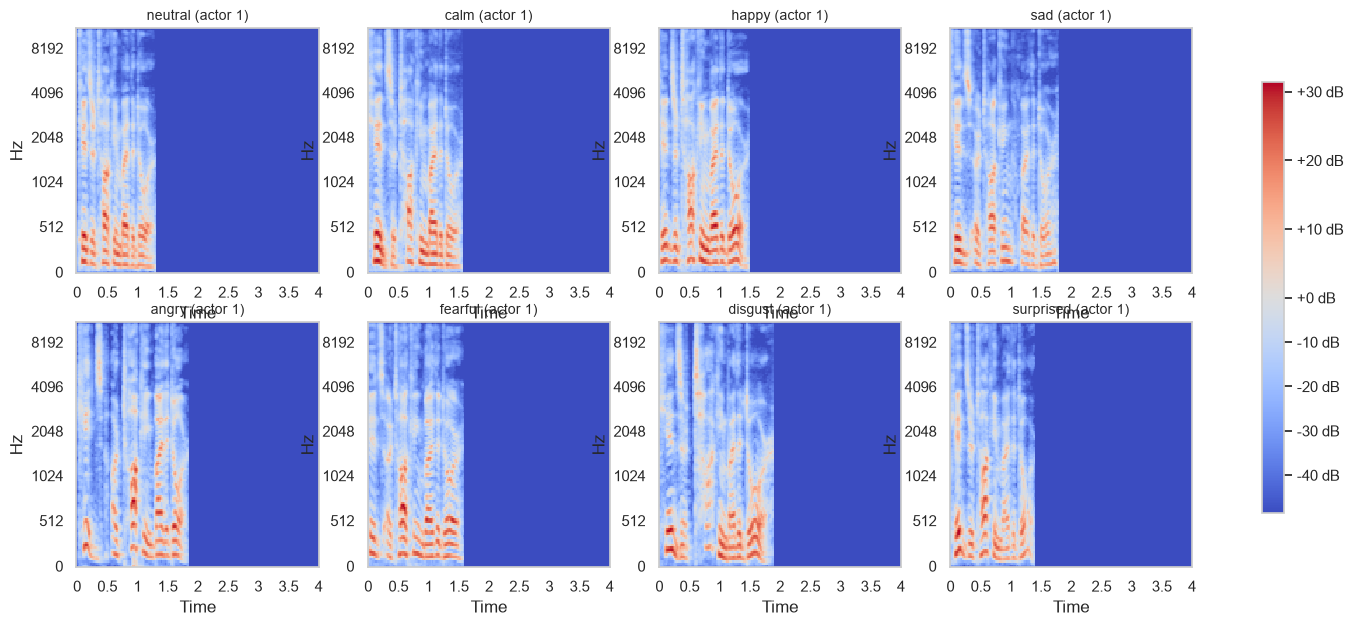

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, emo in zip(axes.ravel(), EMOTIONS):
    i = lab[lab["emotion"] == emo].index[0]
    img = librosa.display.specshow(X[i], sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"{emo} (actor {lab.loc[i, 'actor']})", fontsize=10)
fig.colorbar(img, ax=axes, format="%+2.0f dB", shrink=0.8)
plt.savefig("../images/logmel_examples.png", dpi=140, bbox_inches="tight")
plt.show()

The spectrograms look like proper speech: harmonic bands at low frequencies, energy bursts for each syllable, and a flat floor at the right edge where the clip was padded.

# 6. Normalization (training statistics only)



In [16]:
is_train = (lab["split"] == "train").values
frame_idx = np.arange(N_FRAMES)[None, :]
valid = frame_idx < lab["n_valid_frames"].values[:, None]       # (n_clips, 173) True = real audio

Xtr = X[is_train]                                               # (n_train, 128, 173)
vals = Xtr.transpose(0, 2, 1)[valid[is_train]]                  # (n_valid_frames_total, 128)
MEAN, STD = float(vals.mean()), float(vals.std())
print(f"Training mean = {MEAN:.3f} dB, std = {STD:.3f} dB (from {int(is_train.sum())} training clips)")

Xn = ((X - MEAN) / STD).astype(np.float32)

Training mean = -17.165 dB, std = 15.781 dB (from 899 training clips)


Check that the training data is standardized, and that validation and test only roughly follow it (they must **not** be exactly 0 and 1, that would mean their statistics were used).

train normalized valid frames: mean = +0.000, std = 1.000
val   normalized valid frames: mean = -0.054, std = 1.019
test  normalized valid frames: mean = -0.053, std = 1.031


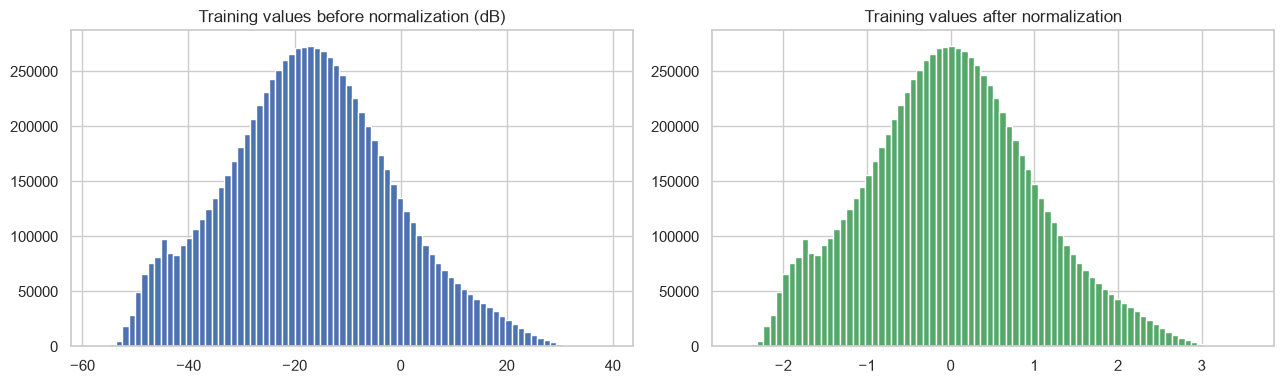

In [17]:
for s in ["train", "val", "test"]:
    m = (lab["split"] == s).values
    v = Xn[m].transpose(0, 2, 1)[valid[m]]
    print(f"{s:5s} normalized valid frames: mean = {v.mean():+.3f}, std = {v.std():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(vals.ravel(), bins=80, color="#4C72B0")
axes[0].set_title("Training values before normalization (dB)")
vn = Xn[is_train].transpose(0, 2, 1)[valid[is_train]]
axes[1].hist(vn.ravel(), bins=80, color="#55A868")
axes[1].set_title("Training values after normalization")
plt.tight_layout()
plt.savefig("../images/logmel_normalization_hist.png", dpi=140)
plt.show()

The histogram keeps its shape (normalization is a linear shift and scale) but is now centered at 0 with a standard deviation of 1. Validation and test values are close to, but not exactly, 0 and 1, as expected when only training statistics are used.

# 7. Save the arrays, statistics and labels

In [18]:
np.save("../data/X_logmel_raw.npy", X)
np.save("../data/X_logmel_norm.npy", Xn)
np.save("../data/norm_stats.npy", np.array([MEAN, STD]))
with open("../data/label_map.json", "w") as f:
    json.dump(LABEL2ID, f, indent=2)

keep = ["filename", "actor", "gender", "emotion", "label", "intensity", "split", "n_valid_frames"]
lab[keep].to_csv("../data/labels.csv", index=False)

print("X_logmel_norm.npy:", Xn.shape, "| size %.0f MB" % (Xn.nbytes / 1e6))
print("Row i of the array = row i of labels.csv")

X_logmel_norm.npy: (1439, 128, 173) | size 127 MB
Row i of the array = row i of labels.csv


The `.npy` files are large (about 130 MB each) and are **not committed to GitHub**. They are listed in `.gitignore` and are regenerated by running this notebook. Phase 2 loads them like this:

```python
X = np.load("data/X_logmel_norm.npy")          # (n_clips, 128, 173)
labels = pd.read_csv("data/labels.csv")
X_train = X[labels["split"] == "train"]
y_train = labels.loc[labels["split"] == "train", "label"].values
```
